<a href="https://colab.research.google.com/github/medericl/DocTokenClassifier/blob/main/S4_encoders_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DLIM S4 — Contextual encoders for document labeling

**1h lecture + 3h lab; two weeks to finish individually.** Author: J. Chazalon.

We reuse one task throughout: classify each supplied document word as **question (field label), answer (field value), header, or other**. We do not train OCR or predict question–answer relations.

Path: ModernBERT MLM → compact BERT token classifier → spatial tokens → additive spatial embeddings. Complete stages 1–4 in class; stages 5–6 are progressive homework if time is short. All students follow the same path.

The primary deliverable is `predictions_test.json` indexed by original word IDs, plus your notebook and validation/error analysis. FUNSD test annotations are public: this is a course evaluation, not a private benchmark. Do not use test labels to choose models or settings.

Sources: [FUNSD](https://guillaumejaume.github.io/FUNSD/), [HF token classification](https://huggingface.co/docs/transformers/tasks/token_classification), [spatial-token paper](https://arxiv.org/abs/2302.08948).


## 1. Setup and data — 15 min

Colab: select a GPU runtime. Kaggle: select one GPU accelerator and enable Internet. Run this installation cell **before importing Transformers**. Keep the platform's PyTorch; no OCR, FlashAttention or Trainer is required.

The notebook contains its helpers and works without cloning the repository. Downloads/caches go to `/tmp/dlim-s4`; exported predictions go to the notebook's working directory. Download your results before the session ends.


In [1]:
import sys, subprocess, importlib.metadata, os
from pathlib import Path
os.environ.setdefault("HF_HOME", str(Path("/tmp") / "dlim-s4" / "hf"))
os.environ.setdefault("HF_HUB_DISABLE_XET", "1")
try:
    installed = importlib.metadata.version("transformers")
except importlib.metadata.PackageNotFoundError:
    installed = None
if installed != "4.57.1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "transformers==4.57.1"])
# If Transformers was already imported before installation, restart the runtime, then Run all.
import torch, transformers
print("Python", sys.version.split()[0], "Torch", torch.__version__, "Transformers", transformers.__version__)
if tuple(int(x) for x in torch.__version__.split("+")[0].split(".")[:2]) < (2, 6):
    raise RuntimeError("This checkpoint requires PyTorch >=2.6. Use a current Colab/Kaggle image or update PyTorch and restart.")
print("GPU", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
    torch.set_num_threads(min(4, os.cpu_count() or 1))
    print("CPU route: use short runs or the supplied instructor checkpoints.")


Python 3.13.15 Torch 2.11.0+cu130 Transformers 4.57.1
GPU Tesla T4


### Provided helper tools

Run this cell as supplied. It loads images/words, creates common word windows, batches examples, plots pages and scores predictions. The meaningful exercises are below. Geometry-only sorting is a simple baseline for reading order; it can mix columns.


In [2]:
"""Provided tools for DLIM S4. Also embedded in the self-contained notebooks."""
from collections.abc import Mapping, Sequence
from typing import Any
from pathlib import Path
import io
import json
import random
import tempfile
import time
import urllib.request
import zipfile

import numpy as np
import torch
from torch import nn
from PIL import Image
import matplotlib.pyplot as plt
from transformers import AutoModel, AutoTokenizer

LABELS = ["other", "header", "question", "answer"]
LABEL2ID = {name: i for i, name in enumerate(LABELS)}
MODEL_ID = "google/bert_uncased_L-4_H-256_A-4"
MODEL_REVISION = "387825ce42dbb39b87911cdf8e383ee3b25184f8"
MLM_REVISION = "8949b909ec900327062f0ebf497f51aef5e6f0c8"
DATA_URL = "https://guillaumejaume.github.io/FUNSD/dataset.zip"
DATA_DIR = Path(tempfile.gettempdir()) / "dlim-s4"
BINS = 16
SPATIAL_TOKENS = [f"<X_{i:02d}>" for i in range(BINS)] + [f"<Y_{i:02d}>" for i in range(BINS)]


def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def load_funsd(archive=None, include_test_labels=False):
    """Read ZIP directly: no extraction, OCR, datasets package or label-based ordering."""
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    path = Path(archive) if archive else DATA_DIR / "funsd.zip"
    if not path.exists():
        print("Downloading FUNSD (~17 MB)...")
        temp = path.with_suffix(".part")
        urllib.request.urlretrieve(DATA_URL, temp)
        temp.replace(path)
    pages = {"training_data": [], "testing_data": []}
    with zipfile.ZipFile(path) as z:
        names = sorted(n for n in z.namelist() if n.startswith("dataset/")
                       and "/annotations/" in n and n.endswith(".json")
                       and not Path(n).name.startswith("._"))
        for name in names:
            split = name.split("/")[1]
            page_id = Path(name).stem
            image_name = name.replace("/annotations/", "/images/").replace(".json", ".png")
            image = Image.open(io.BytesIO(z.read(image_name))).convert("RGB")
            annotation = json.loads(z.read(name))
            words = []
            source_index = 0
            for entity in annotation["form"]:
                for word in entity["words"]:
                    if word["text"].strip():
                        words.append({"word_id": source_index, "text": word["text"],
                                      "box": word["box"], "label": LABEL2ID[entity["label"]]})
                    source_index += 1
            # A simple geometry-only order; multi-column order is intentionally not perfect.
            words.sort(key=lambda w: ((w["box"][1] + w["box"][3]) // 2, w["box"][0], w["word_id"]))
            pages[split].append({"page_id": page_id, "image": image, "words": words})
    # Fixed page split: no word/chunk from a validation page occurs in training.
    indices = list(range(len(pages["training_data"])))
    random.Random(42).shuffle(indices)
    val_indices = set(indices[:30])
    train = [p for i, p in enumerate(pages["training_data"]) if i not in val_indices]
    val = [p for i, p in enumerate(pages["training_data"]) if i in val_indices]
    test = [{"page_id": p["page_id"], "image": p["image"],
             "words": [{k: v for k, v in w.items() if k != "label"} for w in p["words"]]}
            for p in pages["testing_data"]]
    if include_test_labels:
        test = pages["testing_data"]
    return train, val, test


def geometry_bins(box: Sequence[int | float], width: int, height: int) -> tuple[int, int]:
    x = (box[0] + box[2]) / (2 * width)
    y = (box[1] + box[3]) / (2 * height)
    return min(BINS - 1, max(0, int(BINS * x))), min(BINS - 1, max(0, int(BINS * y)))


def show_page(page, predictions=None, limit=None):
    colors = ["gray", "purple", "royalblue", "darkorange"]
    fig, ax = plt.subplots(figsize=(9, 12))
    ax.imshow(page["image"])
    for word in page["words"][:limit]:
        value = predictions[word["word_id"]] if predictions is not None else word.get("label", 0)
        x0, y0, x1, y1 = word["box"]
        ax.add_patch(plt.Rectangle((x0, y0), x1-x0, y1-y0, fill=False,
                                  edgecolor=colors[value], linewidth=1))
    ax.set_title(page["page_id"] + " | " + " / ".join(LABELS))
    ax.axis("off")
    return fig


def make_tokenizer(model_id=MODEL_ID):
    revision = MODEL_REVISION if model_id == MODEL_ID else None
    tokenizer = AutoTokenizer.from_pretrained(model_id, revision=revision, use_fast=True)
    tokenizer.add_special_tokens({"additional_special_tokens": SPATIAL_TOKENS})
    return tokenizer


def align_first_subwords(word_ids: Sequence[int | None], expanded_word_labels: Sequence[int], expanded_to_source: Sequence[int | None]) -> tuple[list[int], list[int | None]]:
    return student_align(word_ids, expanded_word_labels, expanded_to_source)


def encode_words(page, words, tokenizer, mode, align_fn=align_first_subwords):
    """Keep explicit marker-to-word mapping: word_ids alone also indexes marker strings."""
    expanded, roles, mapping, spatial = [], [], [], []
    width, height = page["image"].size
    for word in words:
        x, y = geometry_bins(word["box"], width, height)
        if mode == "tokens":
            expanded.extend([f"<X_{x:02d}>", f"<Y_{y:02d}>"])
            roles.extend([-100, -100])
            mapping.extend([None, None])
            spatial.extend([(0, 0), (0, 0)])
        expanded.append(word["text"])
        roles.append(word.get("label", -100))
        mapping.append(word["word_id"])
        # Reserve 0 for special tokens and padding.
        spatial.append((x + 1, y + 1))
    encoding = tokenizer(expanded, is_split_into_words=True, truncation=False)
    word_ids = encoding.word_ids()
    labels, sources = align_fn(word_ids, roles, mapping)
    encoding["labels"] = labels
    encoding["spatial"] = [spatial[i] if i is not None else (0, 0) for i in word_ids]
    encoding["sources"] = sources
    encoding["page_id"] = page["page_id"]
    return dict(encoding)


def make_windows(pages, tokenizer, max_length=256, word_limit=48):
    """Use the largest (token-insertion) representation to define common word windows."""
    result = []
    for page in pages:
        start = 0
        while start < len(page["words"]):
            end = min(start + word_limit, len(page["words"]))
            while end > start and len(encode_words(page, page["words"][start:end], tokenizer, "tokens")["input_ids"]) > max_length:
                end -= 1
            if end == start:
                raise ValueError("One word exceeds the token budget; inspect it before changing limits.")
            result.append((page, page["words"][start:end]))
            start = end
    return result


class WordDataset(torch.utils.data.Dataset):
    def __init__(self, windows, tokenizer, mode="text", align_fn=align_first_subwords):
        self.items = [encode_words(p, w, tokenizer, mode, align_fn) for p, w in windows]

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        return self.items[index]


def collate_words(items, tokenizer):
    keys = ["input_ids", "attention_mask"]
    if "token_type_ids" in items[0]:
        keys.append("token_type_ids")
    batch = tokenizer.pad([{k: x[k] for k in keys} for x in items], return_tensors="pt")
    length = batch["input_ids"].shape[1]
    batch["labels"] = torch.tensor([x["labels"] + [-100] * (length-len(x["labels"])) for x in items])
    batch["spatial"] = torch.tensor([x["spatial"] + [(0, 0)] * (length-len(x["spatial"])) for x in items])
    batch["metadata"] = [(x["page_id"], x["sources"]) for x in items]
    return batch


def spatial_sum(x_embedding: nn.Embedding, y_embedding: nn.Embedding, spatial: torch.Tensor) -> torch.Tensor:
    raise NotImplementedError("Complete the corresponding exercise below")


class SpatialClassifier(nn.Module):
    def __init__(self, tokenizer, mode="text", model_id=MODEL_ID, spatial_fn=spatial_sum):
        super().__init__()
        self.mode = mode
        kwargs = {"attn_implementation": "eager", "revision": MODEL_REVISION if model_id == MODEL_ID else None}
        if "ModernBERT" in model_id:
            kwargs["reference_compile"] = False
        self.backbone = AutoModel.from_pretrained(model_id, **kwargs)
        self.backbone.resize_token_embeddings(len(tokenizer), mean_resizing=False)
        hidden = self.backbone.config.hidden_size
        self.classifier = nn.Linear(hidden, len(LABELS))
        self.x_embedding = nn.Embedding(BINS + 1, hidden, padding_idx=0)
        self.y_embedding = nn.Embedding(BINS + 1, hidden, padding_idx=0)
        nn.init.normal_(self.x_embedding.weight, std=0.01)
        nn.init.normal_(self.y_embedding.weight, std=0.01)
        with torch.no_grad():
            self.x_embedding.weight[0].zero_()
            self.y_embedding.weight[0].zero_()
        self.spatial_fn = spatial_fn
        if mode != "embeddings":
            self.x_embedding.requires_grad_(False)
            self.y_embedding.requires_grad_(False)

    def forward(self, input_ids, attention_mask, spatial, token_type_ids=None):
        kwargs = {"attention_mask": attention_mask}
        if token_type_ids is not None and self.backbone.config.model_type == "bert":
            kwargs["token_type_ids"] = token_type_ids
        if self.mode == "embeddings":
            inputs = self.backbone.get_input_embeddings()(input_ids)
            inputs = inputs + self.spatial_fn(self.x_embedding, self.y_embedding, spatial)
            kwargs["inputs_embeds"] = inputs
        else:
            kwargs["input_ids"] = input_ids
        return self.classifier(self.backbone(**kwargs).last_hidden_state)


def model_batch(batch, device):
    return {k: v.to(device) for k, v in batch.items()
            if k in {"input_ids", "attention_mask", "spatial", "token_type_ids"}}


def train_step(model: nn.Module, batch: Mapping[str, Any], optimizer: torch.optim.Optimizer, device: torch.device | str) -> float:
    raise NotImplementedError("Complete the corresponding exercise below")


def score_words(predictions, pages):
    confusion = np.zeros((len(LABELS), len(LABELS)), dtype=np.int64)
    for page in pages:
        for word in page["words"]:
            confusion[word["label"], predictions[page["page_id"]][word["word_id"]]] += 1
    tp = confusion.diagonal()
    precision = tp / np.maximum(confusion.sum(axis=0), 1)
    recall = tp / np.maximum(confusion.sum(axis=1), 1)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    return {"macro_f1": float(f1.mean()), "accuracy": float(tp.sum() / max(confusion.sum(), 1)),
            "per_class_f1": dict(zip(LABELS, f1.tolist())), "confusion": confusion.tolist()}


@torch.no_grad()
def predict_words(model, loader, device):
    model.eval()
    result = {}
    for batch in loader:
        labels = model(**model_batch(batch, device)).argmax(dim=-1).cpu().tolist()
        for values, (page_id, sources) in zip(labels, batch["metadata"]):
            page_result = result.setdefault(page_id, {})
            for value, source in zip(values, sources):
                if source is not None:
                    if source in page_result:
                        raise ValueError("Duplicated original word ID")
                    page_result[source] = value
    return result


def fit(model, loader, val_loader, val_pages, device, steps=120, learning_rate=5e-5, step_fn=train_step):
    model.to(device)
    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=learning_rate)
    iterator = iter(loader)
    start = time.perf_counter()
    history = []
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    for step in range(1, steps+1):
        try:
            batch = next(iterator)
        except StopIteration:
            iterator = iter(loader)
            batch = next(iterator)
        loss = step_fn(model, batch, optimizer, device)
        if step % 40 == 0 or step == steps:
            scores = score_words(predict_words(model, val_loader, device), val_pages)
            history.append({"step": step, "loss": loss, "seconds": time.perf_counter()-start,
                            "macro_f1": scores["macro_f1"]})
            print(history[-1])
    return {"history": history, "seconds": time.perf_counter()-start,
            "peak_gpu_bytes": torch.cuda.max_memory_allocated() if device.type == "cuda" else None}


def export_predictions(predictions, pages, path="predictions_test.json"):
    output = []
    for page in pages:
        expected = {w["word_id"] for w in page["words"]}
        actual = predictions.get(page["page_id"], {})
        if set(actual) != expected:
            raise ValueError(f"Missing/extra predictions on {page['page_id']}")
        output.append({"page_id": page["page_id"], "predictions": [
            {"word_id": i, "label": LABELS[actual[i]]} for i in sorted(expected)]})
    Path(path).write_text(json.dumps(output, indent=2))
    return Path(path).resolve()


def save_checkpoint(model, tokenizer, path):
    path = Path(path)
    path.mkdir(parents=True, exist_ok=True)
    # Standalone backbone files permit loading without network from attached assets.
    model.backbone.save_pretrained(path / "backbone")
    tokenizer.save_pretrained(path / "tokenizer")
    torch.save({"mode": model.mode, "state_dict": model.cpu().state_dict(), "labels": LABELS}, path / "classifier.pt")
    return path.resolve()


def load_checkpoint(path, spatial_fn=spatial_sum):
    path = Path(path)
    state = torch.load(path / "classifier.pt", map_location="cpu", weights_only=True)
    if state["labels"] != LABELS:
        raise ValueError("Checkpoint label inventory differs from this lab")
    tokenizer = AutoTokenizer.from_pretrained(path / "tokenizer", use_fast=True)
    model = SpatialClassifier(tokenizer, mode=state["mode"], model_id=str(path / "backbone"), spatial_fn=spatial_fn)
    model.load_state_dict(state["state_dict"])
    return model, tokenizer


Pages: 119 30 50
Labels: ['other', 'header', 'question', 'answer']
Example word: {'word_id': 0, 'text': 'R&D', 'box': [292, 91, 376, 175], 'label': 0}


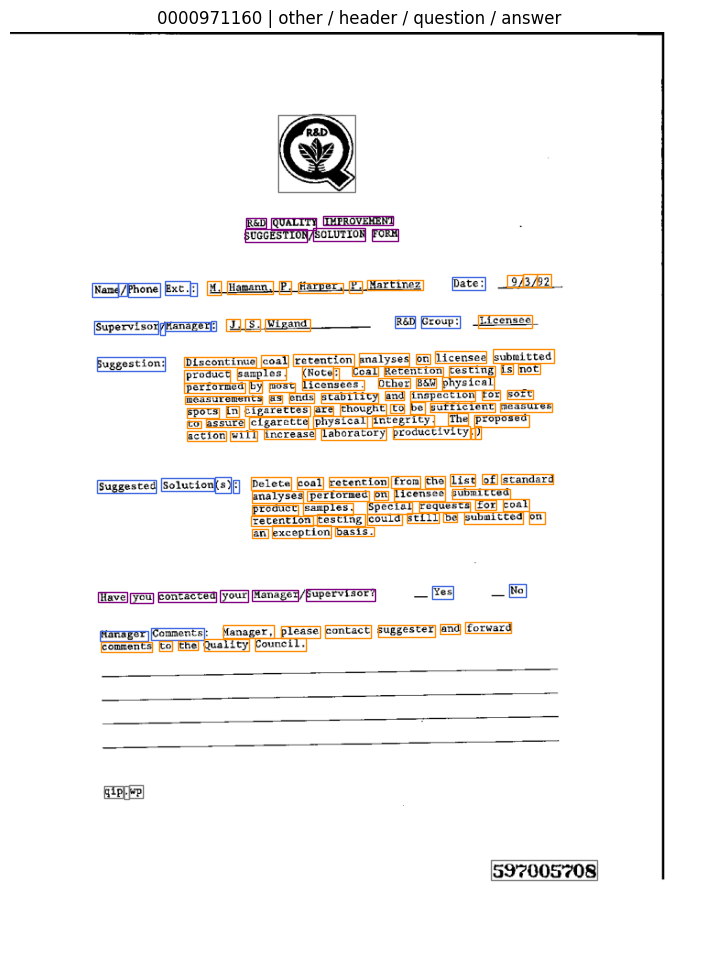

In [3]:
seed_everything(42)
# To use an attached ZIP on Kaggle, set ARCHIVE to its /kaggle/input/... path.
ARCHIVE = None
train_pages, val_pages, test_pages = load_funsd(ARCHIVE)
print("Pages:", len(train_pages), len(val_pages), len(test_pages))
print("Labels:", LABELS)
print("Example word:", train_pages[0]["words"][0])
show_page(train_pages[0])
plt.show()


**Questions:** What is provided at inference? Which fields are supervision? Why split by page? Why must entity links and ground-truth entity IDs not enter the model?

A word label comes from its containing annotated entity. Empty words are removed. The published entity extraction task often uses seven BIO labels; here we collapse boundary information to four roles. BIO will be revisited in the lecture.

## 2. ModernBERT: masking and context — 15 min

A masked-language-model head predicts vocabulary IDs. A token-classification head predicts the four task labels. The encoder produces contextual vectors in both cases. ModernBERT is the demonstration model; a smaller BERT keeps the required training manageable.


In [4]:
from transformers import AutoModelForMaskedLM, AutoTokenizer
import gc
MLM_ID = "answerdotai/ModernBERT-base"
mlm_tokenizer = AutoTokenizer.from_pretrained(MLM_ID, revision=MLM_REVISION)
mlm_model = AutoModelForMaskedLM.from_pretrained(
    MLM_ID, revision=MLM_REVISION, attn_implementation="eager", reference_compile=False).to(device).eval()
text = "The capital of France is " + mlm_tokenizer.mask_token + "."
mlm_inputs = mlm_tokenizer(text, return_tensors="pt").to(device)
with torch.no_grad():
    mlm_output = mlm_model(**mlm_inputs, output_hidden_states=True)
print("Token IDs:", mlm_inputs["input_ids"])
print("Logits:", mlm_output.logits.shape, "Context vectors:", mlm_output.hidden_states[-1].shape)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/599M [00:00<?, ?B/s]

Token IDs: tensor([[50281,   510,  5347,   273,  6181,   310, 50284,    15, 50282]],
       device='cuda:0')
Logits: torch.Size([1, 9, 50368]) Context vectors: torch.Size([1, 9, 768])


### Exercise 1 — Inspect the prediction

Find the mask position; select its vocabulary logits; apply softmax and display the five largest probabilities. Repeat with another sentence and explain the difference. Does a likely word establish factual truth?

**Hint 1:** logits have shape `(batch, sequence, vocabulary)`.
**Hint 2:** compare `input_ids` with `mask_token_id`; use `softmax(-1)` and `topk(5)`.


In [5]:
# TODO: find the mask position and display the top five predictions.

def top5(text):
  inputs = mlm_tokenizer(text, return_tensors="pt").to(device) # dict : "input_ids": ..., "attention_mask": ...

  with torch.no_grad():
        print(mlm_tokenizer.decode(inputs["input_ids"][0]))
        output = mlm_model(**inputs) # output.logits -> (batch, sequence, vocabulary)
        mask_pos = (inputs["input_ids"] == mlm_tokenizer.mask_token_id).nonzero()[0,1]
        values, indices = output.logits[0, mask_pos].softmax(-1).topk(5) # top 5
        print(values)
        tokens = mlm_tokenizer.convert_ids_to_tokens(indices)
        print(tokens)
        print()

top5("The capital of France is " + mlm_tokenizer.mask_token + ".")
top5("The capital of Australia is " + mlm_tokenizer.mask_token + ".")
# Does a likely word establish factual truth? -> No

[CLS]The capital of France is[MASK].[SEP]
tensor([0.9233, 0.0359, 0.0231, 0.0062, 0.0026], device='cuda:0')
['ĠParis', 'ĠLyon', 'ĠNancy', 'ĠNice', 'ĠOrleans']

[CLS]The capital of Australia is[MASK].[SEP]
tensor([0.4106, 0.2045, 0.1595, 0.0945, 0.0726], device='cuda:0')
['ĠSydney', 'ĠMelbourne', 'ĠAdelaide', 'ĠBrisbane', 'ĠPerth']



In [6]:
del mlm_model, mlm_output, mlm_inputs
gc.collect()
if device.type == "cuda":
    torch.cuda.empty_cache()


### Exercise 2 — Align targets

Implement `student_align`: output one label and original-word ID at the first subword of a real word. All other positions get label `-100` and source ID `None`.

**Worked example (illustrative tokenization):** expanded input items are
`["<X_06>", "Date:", "May"]`. The marker has no original-word ID;
`Date:` and `May` have original-word IDs `27` and `28`.
Role IDs are `question = 2` and `answer = 3`.

```python
# One entry per expanded input item (not per model token):
expanded_word_labels = [-100, 2, 3]
expanded_to_source = [None, 27, 28]

# One entry per model token:
# Tokens:   [CLS]  <X_06>  date  :  may  [SEP]
word_ids = [None,     0,     1, 1,   2,   None]

# Expected return value: (labels, sources)
labels  = [-100, -100,  2, -100,  3, -100]
sources = [None, None, 27, None, 28, None]
```

`word_ids` indexes the expanded input items; `sources` identifies original
FUNSD words. The first `Date:` subword (`date`) gets the word's target and ID;
its second subword (`:`) is ignored. The marker has an expanded-item index
but no original-word ID, so it is ignored too. Both returned lists have
`len(word_ids)` entries. Ignored targets do not remove tokens from input context.

**Hint 1:** `word_index is None` means a tokenizer-added special position.
**Hint 2:** an inserted geometry marker has source `None` too.
**Hint 3:** compare the current word index to the previous index to identify first subwords.


In [7]:
def student_align(word_ids: Sequence[int | None], expanded_word_labels: Sequence[int], expanded_to_source: Sequence[int | None]) -> tuple[list[int], list[int | None]]:
    """Return two lists of len(word_ids): integer targets and original-word IDs (or None)."""
    # TODO: return (labels, sources), aligned with token positions.
    sources = []
    labels = []
    s = set()
    for pos, word_index in enumerate(word_ids):
        if (word_index is None):
            labels.append(-100)
            sources.append(None)

        elif word_index not in s and expanded_to_source[word_index] is not None:
            s.add(word_index)
            sources.append(expanded_to_source[word_index])
            labels.append(expanded_word_labels[word_index])
        else:
            labels.append(-100)
            sources.append(None)

    return labels, sources

## 3. Words, subwords and supervision — 20 min

A word can become several model tokens. We supervise its first subword and ignore the remaining subwords, special tokens, inserted geometry markers and padding with label `-100`.

The helper also tracks **original word IDs**. Those IDs do not change when spatial tokens are inserted. A tokenizer may assign word IDs to inserted marker strings: use the provided `expanded_to_source` map, not only `word_ids()`.


In [8]:
tokenizer = make_tokenizer()
MAX_LENGTH = 256
train_windows = make_windows(train_pages, tokenizer, MAX_LENGTH)
val_windows = make_windows(val_pages, tokenizer, MAX_LENGTH)
test_windows = make_windows(test_pages, tokenizer, MAX_LENGTH)
print("Word windows:", len(train_windows), len(val_windows), len(test_windows))
# Windows fit even the longest representation (two extra markers per word).


config.json:   0%|          | 0.00/383 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

Word windows: 420 108 206


In [9]:
from functools import partial
from torch.utils.data import DataLoader
collate = partial(collate_words, tokenizer=tokenizer)
def loaders_for(mode):
    train_data = WordDataset(train_windows, tokenizer, mode, align_fn=student_align)
    val_data = WordDataset(val_windows, tokenizer, mode, align_fn=student_align)
    return (DataLoader(train_data, batch_size=4, shuffle=True, collate_fn=collate, num_workers=0),
            DataLoader(val_data, batch_size=4, shuffle=False, collate_fn=collate, num_workers=0))
train_loader, val_loader = loaders_for("text")
batch = next(iter(train_loader))
print({k: tuple(v.shape) for k, v in batch.items() if isinstance(v, torch.Tensor)})
assert (batch["labels"] != -100).sum() > 0
example = WordDataset(val_windows[:1], tokenizer, "text", align_fn=student_align)[0]
print(list(zip(tokenizer.convert_ids_to_tokens(example["input_ids"][:18]), example["labels"][:18], example["sources"][:18])))


You're using a BertTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


{'input_ids': (4, 127), 'attention_mask': (4, 127), 'token_type_ids': (4, 127), 'labels': (4, 127), 'spatial': (4, 127, 2)}
[('[CLS]', -100, None), ('page', 0, 34), ('1', 0, 35), ('of', 0, 36), ('10', 0, 37), ('restricted', 1, 38), ('brown', 1, 39), ('&', 1, 40), ('williamson', 1, 41), ('tobacco', 1, 43), ('international', 1, 42), ('product', 1, 44), ('specification', 1, 45), ('phoenix', 3, 2), ('brand', 2, 0), (':', -100, None), ('company', 2, 3), (':', -100, None)]


## 4. Train the text-only classifier — 45 min

Our compact encoder is `google/bert_uncased_L-4_H-256_A-4`. Add a linear classifier to each contextual vector. The supplied model wrapper will later accept additional spatial vectors. All variants start from the same base model and seed.

### Exercise 3 — One training step

Implement forward, cross-entropy over valid labels, backward and optimizer update. Return the scalar loss. We give gradient clipping to keep the short run stable.

**Hint 1:** flatten logits to `(tokens, classes)` and labels to `(tokens,)`.
**Hint 2:** use `ignore_index=-100`; cross-entropy expects logits, not softmax probabilities.
**Hint 3:** zero gradients each step and use `loss.backward()` before `optimizer.step()`.


In [10]:
def student_train_step(model: nn.Module, batch: Mapping[str, Any], optimizer: torch.optim.Optimizer, device: torch.device | str) -> float:
    """Return the detached scalar loss as a Python float after the optimizer update."""
    # TODO: training mode, zero gradients, forward, loss, backward, update.
    model.train() # training mode
    optimizer.zero_grad() # zero gradients
    logits = model(**model_batch(batch, device))
    labels = batch["labels"].to(device)
    loss = nn.functional.cross_entropy(logits.reshape(-1, logits.shape[-1]),labels.reshape(-1),ignore_index=-100,) # flatten
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step() # update the weigths
    return loss.item()


pytorch_model.bin:   0%|          | 0.00/45.1M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/45.1M [00:00<?, ?B/s]

{'step': 40, 'loss': 0.9222658276557922, 'seconds': 2.8210203280000314, 'macro_f1': 0.2930543082959223}
{'step': 80, 'loss': 1.0138204097747803, 'seconds': 4.491995205999956, 'macro_f1': 0.45052146904804347}
{'step': 120, 'loss': 1.224082112312317, 'seconds': 5.433145661000026, 'macro_f1': 0.43578060499135973}
{'step': 160, 'loss': 0.9925385117530823, 'seconds': 6.3598009370000455, 'macro_f1': 0.4968316622517413}
{'step': 200, 'loss': 0.9658830761909485, 'seconds': 7.209058316999972, 'macro_f1': 0.549646296455647}
{'step': 240, 'loss': 0.5178735852241516, 'seconds': 8.089251966999996, 'macro_f1': 0.5388564879656335}
{'step': 280, 'loss': 0.6483765840530396, 'seconds': 9.009909932000028, 'macro_f1': 0.5475005941055301}
{'step': 320, 'loss': 0.42003557085990906, 'seconds': 9.890587323999966, 'macro_f1': 0.5486731303977762}
{'step': 360, 'loss': 0.4865119159221649, 'seconds': 10.805684757999984, 'macro_f1': 0.5664369127979744}
{'step': 400, 'loss': 1.0130629539489746, 'seconds': 11.715355

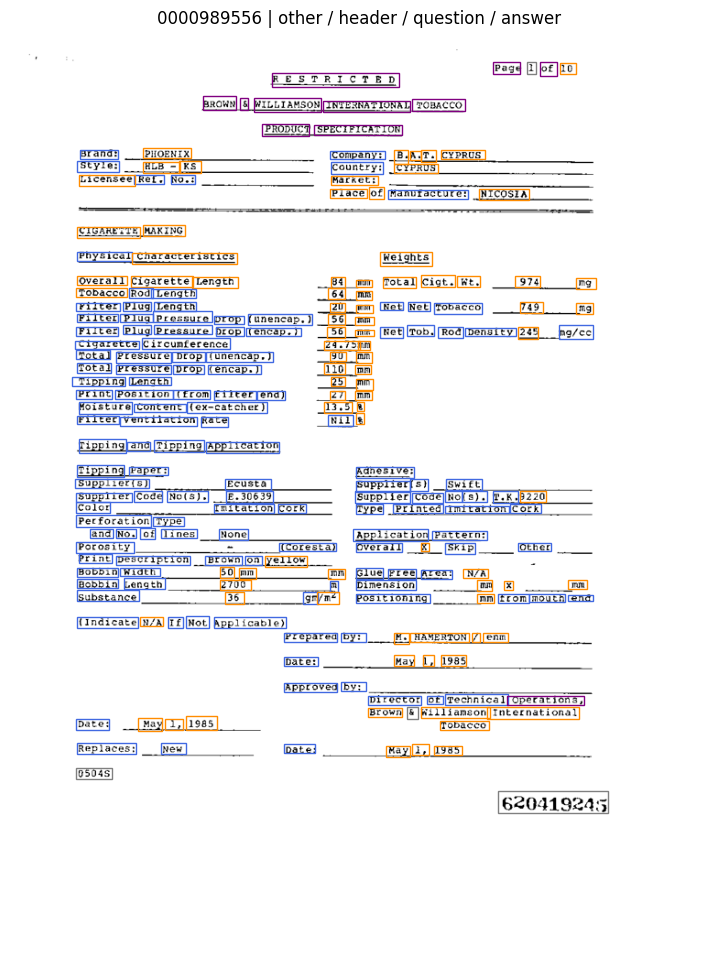

In [11]:
STEPS = 400  # Increase for homework after checking validation; never tune on test labels.
seed_everything(42)
text_model = SpatialClassifier(tokenizer, mode="text")
text_run = fit(text_model, train_loader, val_loader, val_pages, device,
               steps=STEPS, step_fn=student_train_step)
text_predictions = predict_words(text_model, val_loader, device)
print(score_words(text_predictions, val_pages))
show_page(val_pages[0], text_predictions[val_pages[0]["page_id"]])
plt.show()
# Keep trained models on CPU when working on the next variant.
text_model.cpu()
if device.type == "cuda":
    torch.cuda.empty_cache()


**Questions:** Which roles are confused?  

Answer / question (349 + 249 errors) and answer / other (249). Headers are often predicted as questions (144/336).

Why is accuracy alone misleading?
Classes are imbalanced (header = 7.5% of words)

What does validation F1 tell us that training loss does not? We do not promise that a short run is fully converged.

## 5. Add spatial tokens — 35 min; homework if needed

Inspired by [Duménieu et al.](https://arxiv.org/abs/2302.08948), turn geometry into vocabulary entries. Here we quantize word-center x/y into 16 bins. This is a FUNSD adaptation, not an exact replication of the directory experiment.

### Exercise 4 — Geometry bins

Inspect `geometry_bins` and `encode_words`. Modify `student_geometry_bins` below to normalize the word center by image width/height, then quantize/clamp to `[0, BINS-1]`. The dataset has original word boxes, not label-derived segment boxes.

**Hint:** `int(BINS * center / image_size)`; clip at `BINS-1` for points on the border.


In [12]:
def student_geometry_bins(box: Sequence[int | float], width: int, height: int) -> tuple[int, int]:
    """box is [left, top, right, bottom] in pixels; return two integers in [0, BINS-1]."""
    # TODO: return quantized center coordinates (x_bin, y_bin).
    center_x = (box[0] + box[2]) / 2
    center_y = (box[1] + box[3]) / 2
    x_bin = (center_x / width) * BINS
    y_bin = (center_y / height) * BINS
    x_bin = max(0, min(BINS - 1, int(x_bin)))
    y_bin = max(0, min(BINS - 1, int(y_bin)))
    return x_bin, y_bin

In [13]:
geometry_bins = student_geometry_bins
p, words = val_windows[0]
plain = encode_words(p, words, tokenizer, "text", align_fn=student_align)
augmented = encode_words(p, words, tokenizer, "tokens", align_fn=student_align)
print("Token counts:", len(plain["input_ids"]), len(augmented["input_ids"]))
print(tokenizer.convert_ids_to_tokens(augmented["input_ids"][:25]))
assert set(x for x in plain["sources"] if x is not None) == set(x for x in augmented["sources"] if x is not None)
# The tokenizer was already extended by make_tokenizer(), and the model resized by its wrapper.
seed_everything(42)
token_model = SpatialClassifier(tokenizer, mode="tokens")
token_train_loader, token_val_loader = loaders_for("tokens")
token_run = fit(token_model, token_train_loader, token_val_loader, val_pages, device,
                steps=STEPS, step_fn=student_train_step)
token_predictions = predict_words(token_model, token_val_loader, device)
print(score_words(token_predictions, val_pages))
token_model.cpu()
if device.type == "cuda":
    torch.cuda.empty_cache()


Token counts: 72 168
['[CLS]', '<X_11>', '<Y_00>', 'page', '<X_11>', '<Y_00>', '1', '<X_12>', '<Y_00>', 'of', '<X_12>', '<Y_00>', '10', '<X_07>', '<Y_00>', 'restricted', '<X_04>', '<Y_01>', 'brown', '<X_05>', '<Y_01>', '&', '<X_06>', '<Y_01>', 'williamson']
{'step': 40, 'loss': 0.90486079454422, 'seconds': 0.9746905030000335, 'macro_f1': 0.3064643198462518}
{'step': 80, 'loss': 0.9552205801010132, 'seconds': 1.913671718000046, 'macro_f1': 0.43796616898604257}
{'step': 120, 'loss': 1.1950284242630005, 'seconds': 2.87539313100001, 'macro_f1': 0.46543985175455077}
{'step': 160, 'loss': 0.985328197479248, 'seconds': 3.816594251999959, 'macro_f1': 0.4941821850113246}
{'step': 200, 'loss': 0.9566597938537598, 'seconds': 4.738459564999971, 'macro_f1': 0.5225636448425575}
{'step': 240, 'loss': 0.7091339230537415, 'seconds': 5.711062675999983, 'macro_f1': 0.5328625032829581}
{'step': 280, 'loss': 0.619835615158081, 'seconds': 6.691908364000028, 'macro_f1': 0.5315619495067978}
{'step': 320, 'los

## 6. Add spatial embeddings — 30 min; homework if needed

Keep the text sequence length. Before contextualization, add learned x/y embedding vectors to each token's input vector. The word's spatial indices are copied to all its subwords; index zero gives a zero vector for special tokens/padding. The encoder still supplies its usual sequence-position embeddings.

### Exercise 5 — Spatial addition

Return the sum of x and y vectors with shape `(batch, length, hidden)`. Inspect the provided wrapper: it adds your result to the token embedding and passes `inputs_embeds` to the encoder. These tables are learned during fine-tuning; geometry is not automatically understood.

**Hint:** `spatial[..., 0]` and `spatial[..., 1]` contain integer embedding indices.


In [17]:
def student_spatial_sum(x_embedding: nn.Embedding, y_embedding: nn.Embedding, spatial: torch.Tensor) -> torch.Tensor:
    """spatial: integer tensor (B, L, 2); return floating vectors (B, L, hidden)."""
    # TODO: gather and add the x/y embedding vectors.
    x = spatial[:, :, 0]
    y = spatial[:, :, 1]
    return x_embedding(x) + y_embedding(y)



In [18]:
seed_everything(42)
spatial_model = SpatialClassifier(tokenizer, mode="embeddings", spatial_fn=student_spatial_sum)
spatial_train_loader, spatial_val_loader = loaders_for("text")
spatial_run = fit(spatial_model, spatial_train_loader, spatial_val_loader, val_pages, device,
                  steps=STEPS, step_fn=student_train_step)
spatial_predictions = predict_words(spatial_model, spatial_val_loader, device)
print(score_words(spatial_predictions, val_pages))
spatial_model.cpu()


{'step': 40, 'loss': 0.9276587963104248, 'seconds': 0.896953258999929, 'macro_f1': 0.29912014735420456}
{'step': 80, 'loss': 0.9753886461257935, 'seconds': 1.7869850469999164, 'macro_f1': 0.4777152933190217}
{'step': 120, 'loss': 1.139266848564148, 'seconds': 2.6643102460000136, 'macro_f1': 0.45804294346107177}
{'step': 160, 'loss': 1.0417159795761108, 'seconds': 3.598485551000067, 'macro_f1': 0.5131989111936841}
{'step': 200, 'loss': 0.9829366207122803, 'seconds': 4.496660608999946, 'macro_f1': 0.5557540251190938}
{'step': 240, 'loss': 0.5494260191917419, 'seconds': 5.3991391089998615, 'macro_f1': 0.5514599723539432}
{'step': 280, 'loss': 0.6503955125808716, 'seconds': 6.314502708999953, 'macro_f1': 0.5652196600654862}
{'step': 320, 'loss': 0.3888351619243622, 'seconds': 7.198246826000059, 'macro_f1': 0.5577121021944065}
{'step': 360, 'loss': 0.4012598991394043, 'seconds': 8.091072038999982, 'macro_f1': 0.5697057375200285}
{'step': 400, 'loss': 0.9141908884048462, 'seconds': 8.9680582

SpatialClassifier(
  (backbone): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30554, 256, padding_idx=0)
      (position_embeddings): Embedding(512, 256)
      (token_type_embeddings): Embedding(2, 256)
      (LayerNorm): LayerNorm((256,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-3): 4 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=256, out_features=256, bias=True)
              (key): Linear(in_features=256, out_features=256, bias=True)
              (value): Linear(in_features=256, out_features=256, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=256, out_features=256, bias=True)
              (LayerNorm): LayerNorm((256,), eps=1e-12, elementwi

### Interpretation and LayoutLM — 10 min

Record your own validation metrics, wall-clock time and token counts. No class-wide comparison is required. A single short run does not establish a general ranking. Spatial-token length/position changes are a confound; additive geometry is a simplified LayoutLM-inspired branch, not full LayoutLM pretraining.

LayoutLM uses dedicated embeddings of bounding-box coordinates; later versions also use visual representations/tokens. Our experiment shows the input interface before introducing a separately pretrained model. An optional LayoutLM notebook is not required for the graded path.


**Results (validation, 400 steps, seed 42)**

```
             macro-F1  accuracy  header F1  time   token
text         0.562     0.657     0.403      11.7s  72
tokens       0.538     0.620     0.429       9.6s  168
embeddings   0.573     0.655     0.456       9.0s  72
```

**Interpretation**
- Additive embeddings give the best macro-F1. the largest gain is on `header`, which relies on position.
- Spatial tokens underperform text-only: 2.3× longer sequences, 32 new untrained tokens and shifted positions.
- Timings are close because the GPU is not the bottleneck here
- Run noise is ~±0.01–0.02 (text reached 0.576 at 300 steps in another session)

**Homework extension:** train with shuffled spatial features, repeat seeds, explore BIO or use a larger encoder. Keep input/target word coverage and page splits fixed. Do not group tokens by gold entity boxes or feed links/roles into the inputs.

## 7. Submit predictions — 10 min

Choose a trained variant using **validation**. Export all original test words, without marker/padding predictions. Explain the selected variant, training settings and one validation failure case. You have two weeks after the lab to finish; the instructor will announce the exact deadline and grading weights.


In [19]:
# Choose "text", "tokens", or "embeddings" using validation results.
#SELECTED = "text"
SELECTED = "embeddings"
models = {"text": text_model}
if "token_model" in globals(): models["tokens"] = token_model
if "spatial_model" in globals(): models["embeddings"] = spatial_model
selected_model = models[SELECTED].to(device)
test_data = WordDataset(test_windows, tokenizer, "tokens" if SELECTED == "tokens" else "text", align_fn=student_align)
test_loader = DataLoader(test_data, batch_size=4, shuffle=False, collate_fn=collate, num_workers=0)
predictions = predict_words(selected_model, test_loader, device)
print(export_predictions(predictions, test_pages))
# Notebook output files can be downloaded from Colab's Files panel or Kaggle's Output panel.


/content/predictions_test.json
